# 🔢 NumPy Playground: Mastering Vectorized Numerical Computing
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jenil1510/Ml-Engineering-learning/blob/main/01_numpy_playground/numpy_playground.ipynb)

**Author:** Machine Learning Engineering Track  
**Focus:** Vectorized array operations, linear algebra, performance benchmarking, memory internals, and zero-loop numerical problem solving.

---

## 🎯 Learning Objectives & Blueprint
In modern Machine Learning, **NumPy is the lingua franca of computation**. From deep learning tensors in PyTorch and JAX to data preprocessing in Pandas and Scikit-Learn, understanding NumPy at a mechanical level is foundational.

In this notebook, we cover:
1. **The NumPy Mental Model**: Contiguous memory buffers, data types, strides, and memory layouts ($C$ vs Fortran).
2. **Array Creation**: 1D, 2D, and 3D arrays, special matrices, and sequences.
3. **Array Indexing & Slicing**: Basic slicing, strided access, multi-dimensional views, boolean masking, and fancy indexing.
4. **Mathematical & Statistical Operations**: Universal functions (`ufunc`), broadcasting mechanics, axis-specific aggregations, and cumulative reductions.
5. **Array Reshaping & Manipulation**: `reshape`, `ravel` vs `flatten` (views vs copies), transpositions, stacking, and splitting.
6. **Modern Random Number Generation**: `default_rng`, probability distributions, permutations, and reproducibility.
7. **Real-World Numerical Problems (Zero Explicit Loops)**:
   - Vectorized Pairwise Euclidean Distance Matrix.
   - Ordinary Least Squares (OLS) Linear Regression from Scratch.
   - Vectorized 2D Digital Image Convolution (Sliding Window Kernel).
   - Monte Carlo Simulation of Asset Prices (Geometric Brownian Motion).
8. **Performance Benchmarking**: Vectorized NumPy vs Pure Python loops across scales ($10^3$ to $10^6$), timing analysis, and speedup profiling.
9. **Vectorization Takeaways for ML**: Why loops kill ML pipelines and how hardware SIMD/caching powers fast inference and training.

## 📦 Setup & Verification
We initialize our environment and ensure reproducible execution.

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

# Style settings for clean, publication-quality visualizations
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version : {np.__version__}")

Python Version: 3.12.3
NumPy Version : 2.5.4


---
## 🧠 1. The Core Mental Model of NumPy

### Why is a Python list slow for numerical data?
A standard Python `list` is an array of **pointers** to discrete Python objects scattered across memory. Each integer or float in Python is a full-blown PyObject containing reference counts, type metadata, and value payloads (~28 bytes for a single 64-bit integer!).
* **Pointer chasing:** Traversing a Python list incurs CPU cache misses because elements are not adjacent in RAM.
* **Interpreter overhead:** Every arithmetic operation involves dynamic type-checking and bytecode dispatch.

### The NumPy `ndarray`
A NumPy `ndarray` is an interface to a **contiguous block of homogeneous memory** (C-contiguous or Fortran-contiguous):
* Data is stored sequentially in contiguous bytes.
* The array object consists of a lightweight header containing:
  - `dtype`: Data type (e.g., `int32`, `float64`).
  - `shape`: Dimensions of the array (e.g., `(3, 4)`).
  - `strides`: The number of bytes to step in each dimension to reach the next element.

Let's inspect these properties directly:

In [2]:
# Inspecting memory footprint and strides
arr_demo = np.arange(12, dtype=np.int64).reshape(3, 4)

print("Array:")
print(arr_demo)
print(f"Shape        : {arr_demo.shape}")
print(f"Dimensions   : {arr_demo.ndim}")
print(f"Data Type    : {arr_demo.dtype}")
print(f"Item Size    : {arr_demo.itemsize} bytes per element")
print(f"Total Bytes  : {arr_demo.nbytes} bytes")
print(f"Strides      : {arr_demo.strides} (bytes to jump across rows, bytes to jump across columns)")
print(f"Is C-contiguous: {arr_demo.flags['C_CONTIGUOUS']}")

Array:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
Shape        : (3, 4)
Dimensions   : 2
Data Type    : int64
Item Size    : 8 bytes per element
Total Bytes  : 96 bytes
Strides      : (32, 8) (bytes to jump across rows, bytes to jump across columns)
Is C-contiguous: True


---
## 📐 2. Creating 1D, 2D, and 3D Arrays

NumPy provides diverse constructors to generate arrays from literals, predefined constants, uniform ranges, or linear/logarithmic grids.

In [3]:
# 1. 1D Array Creation
arr_1d = np.array([10, 20, 30, 40, 50], dtype=np.float32)

# 2. 2D Array Creation (Matrices)
arr_2d = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.int32)

# 3. 3D Array Creation (Tensors: e.g., Batch x Height x Width or RGB Channels)
arr_3d = np.array([
    [[1, 2], [3, 4]],
    [[5, 6], [7, 8]],
    [[9, 10], [11, 12]]
], dtype=np.int16)

print(f"1D Array: shape={arr_1d.shape}, ndim={arr_1d.ndim}\n{arr_1d}\n")
print(f"2D Array: shape={arr_2d.shape}, ndim={arr_2d.ndim}\n{arr_2d}\n")
print(f"3D Array: shape={arr_3d.shape}, ndim={arr_3d.ndim}\n{arr_3d}")

1D Array: shape=(5,), ndim=1
[10. 20. 30. 40. 50.]

2D Array: shape=(2, 3), ndim=2
[[1 2 3]
 [4 5 6]]

3D Array: shape=(3, 2, 2), ndim=3
[[[ 1  2]
  [ 3  4]]

 [[ 5  6]
  [ 7  8]]

 [[ 9 10]
  [11 12]]]


### Specialized Array Constructors
In ML workflows, we frequently initialize weights, masks, identity matrices, and parameter ranges.

In [4]:
# Zeros, Ones, and Constant Fill
zeros_arr = np.zeros((2, 4), dtype=np.float64)
ones_arr = np.ones((3, 2), dtype=np.float32)
full_arr = np.full((2, 3), fill_value=42.0)

# Identity & Diagonal Matrices (Crucial for covariance matrices & ridge regression)
eye_mat = np.eye(4)

# Linear and Logarithmic Ranges
range_arr = np.arange(0, 20, 3)         # [start, stop, step)
linspace_arr = np.linspace(0.0, 1.0, 5) # 5 evenly spaced points between 0 and 1
logspace_arr = np.logspace(-3, 1, 5)     # 10^-3 to 10^1 (common for learning rates / regularization)

print("Identity Matrix (4x4):\n", eye_mat)
print("Linspace (0 to 1, 5 pts):", linspace_arr)
print("Logspace (10^-3 to 10^1):", logspace_arr)

Identity Matrix (4x4):
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Linspace (0 to 1, 5 pts): [0.   0.25 0.5  0.75 1.  ]
Logspace (10^-3 to 10^1): [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01]


---
## 🔍 3. Array Indexing and Slicing

Understanding the distinction between **views** (zero-copy memory aliases) and **copies** (allocating new memory) is essential for memory efficiency and avoiding subtle bugs in ML pipelines.

1. **Basic Slicing (`arr[start:stop:step]`)**: Returns a **view** sharing the underlying buffer.
2. **Boolean Indexing (`arr[condition]`)**: Selects elements matching a predicate; returns a **copy**.
3. **Fancy / Integer Array Indexing (`arr[[idx1, idx2]]`)**: Selects arbitrary rows or coordinates; returns a **copy**.

In [5]:
# Sample 2D matrix (5x6)
matrix = np.arange(30).reshape(5, 6)
print("Original Matrix (5x6):\n", matrix)

# Basic Slicing: Rows 1 to 3, Columns 2 to 4
slice_view = matrix[1:4, 2:5]
print("\nSubmatrix [1:4, 2:5]:\n", slice_view)

# Verification that basic slicing creates a VIEW
print(f"Does slice_view share memory with matrix? {np.shares_memory(matrix, slice_view)}")

# Modifying view affects the original matrix
slice_view[0, 0] = 999
print(f"Original matrix[1, 2] after modifying slice: {matrix[1, 2]} (demonstrates view sharing)")
matrix[1, 2] = 8 # restore original value

Original Matrix (5x6):
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]
 [24 25 26 27 28 29]]

Submatrix [1:4, 2:5]:
 [[ 8  9 10]
 [14 15 16]
 [20 21 22]]
Does slice_view share memory with matrix? True
Original matrix[1, 2] after modifying slice: 999 (demonstrates view sharing)


### Boolean Indexing & Conditional Filtering
Vectorized conditional selection avoids slow `if-else` loops.

In [6]:
# Boolean Masking: Find elements divisible by 3 and > 10
mask = (matrix % 3 == 0) & (matrix > 10)
print("Boolean Mask:\n", mask)
print("Filtered Elements:", matrix[mask])

# np.where: Conditional assignment (vectorized ternary: condition ? if_true : if_false)
# Useful for thresholding activations (e.g., ReLU or binary classification boundaries)
clipped = np.where(matrix > 20, 20, matrix)
print("\nMatrix thresholded at max value 20 (np.where):\n", clipped)

Boolean Mask:
 [[False False False False False False]
 [False False False False False False]
 [ True False False  True False False]
 [ True False False  True False False]
 [ True False False  True False False]]
Filtered Elements: [12 15 18 21 24 27]

Matrix thresholded at max value 20 (np.where):
 [[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 20 20 20]
 [20 20 20 20 20 20]]


### Fancy Indexing (Integer Array Indexing)
Fancy indexing allows selecting non-contiguous rows, columns, or arbitrary coordinate pairs.

In [7]:
# Select specific rows: row 0, row 2, and row 4
row_subset = matrix[[0, 2, 4]]
print("Selected Rows [0, 2, 4]:\n", row_subset)

# Coordinate selection: elements at (0, 1), (1, 3), and (3, 5)
coords_selected = matrix[[0, 1, 3], [1, 3, 5]]
print("Elements at coordinates (0,1), (1,3), (3,5):", coords_selected)

# np.ix_: Cross-product slicing of specific rows and columns
cross_submatrix = matrix[np.ix_([0, 2, 4], [1, 3, 5])]
print("Submatrix at rows [0,2,4] x cols [1,3,5]:\n", cross_submatrix)

Selected Rows [0, 2, 4]:
 [[ 0  1  2  3  4  5]
 [12 13 14 15 16 17]
 [24 25 26 27 28 29]]
Elements at coordinates (0,1), (1,3), (3,5): [ 1  9 23]
Submatrix at rows [0,2,4] x cols [1,3,5]:
 [[ 1  3  5]
 [13 15 17]
 [25 27 29]]


---
## ⚡ 4. Mathematical and Statistical Operations

### Broadcasting Rules
Broadcasting enables arithmetic operations between arrays of different shapes without copying data.

**The Broadcasting Rule:**
When operating on two arrays, NumPy compares their shapes element-wise, starting with the **trailing (rightmost) dimensions** and working backward:
1. Dimensions are compatible if they are **equal**, or
2. One of the dimensions is **1**.

If dimensions mismatch and neither is 1, a `ValueError: operands could not be broadcast together` is raised.

In [8]:
# Broadcasting Walkthrough
A = np.array([[10, 20, 30],
              [40, 50, 60]]) # Shape: (2, 3)
B = np.array([1, 2, 3])      # Shape: (3,) -> broadcasted to (1, 3) -> replicated along axis 0 to (2, 3)

C = A + B
print("Array A (2, 3):\n", A)
print("Array B (3,):\n", B)
print("A + B (Broadcasting B along rows):\n", C)

# Column-wise broadcasting using np.newaxis
col_vector = np.array([[100], [200]]) # Shape: (2, 1)
D = A + col_vector
print("\nCol Vector (2, 1) + A (2, 3):\n", D)

Array A (2, 3):
 [[10 20 30]
 [40 50 60]]
Array B (3,):
 [1 2 3]
A + B (Broadcasting B along rows):
 [[11 22 33]
 [41 52 63]]

Col Vector (2, 1) + A (2, 3):
 [[110 120 130]
 [240 250 260]]


### Aggregations & Axis-wise Reductions
In Machine Learning, we constantly aggregate features across batches or channels:
- `axis=0`: Collapse rows (compute statistic down each column).
- `axis=1`: Collapse columns (compute statistic across each row).
- `keepdims=True`: Preserve rank for seamless broadcasting.

In [9]:
data = np.array([[1.5, 2.7, 3.2],
                  [4.1, 5.8, 6.4],
                  [7.2, 8.0, 9.9],
                  [2.0, 3.5, 4.1]])

print("Data Matrix (4 samples x 3 features):\n", data)
print("Total Sum            :", np.sum(data))
print("Feature Means (axis=0):", np.mean(data, axis=0))
print("Sample Means  (axis=1):", np.mean(data, axis=1))
print("Feature Std   (axis=0):", np.std(data, axis=0))
print("Feature Min/Max       :", np.min(data, axis=0), np.max(data, axis=0))
print("Argmax per feature    :", np.argmax(data, axis=0))

# Feature Standardization (Z-score normalization) completely vectorized!
means = np.mean(data, axis=0, keepdims=True)
stds = np.std(data, axis=0, keepdims=True)
standardized_data = (data - means) / stds

print("\nVectorized Z-Score Standardized Data (mean ~ 0, std ~ 1):\n", np.round(standardized_data, 3))
print("Check standardized means:", np.round(np.mean(standardized_data, axis=0), 6))
print("Check standardized stds :", np.round(np.std(standardized_data, axis=0), 6))

Data Matrix (4 samples x 3 features):
 [[1.5 2.7 3.2]
 [4.1 5.8 6.4]
 [7.2 8.  9.9]
 [2.  3.5 4.1]]
Total Sum            : 58.4
Feature Means (axis=0): [3.7 5.  5.9]
Sample Means  (axis=1): [2.46666667 5.43333333 8.36666667 3.2       ]
Feature Std   (axis=0): [2.24388057 2.07243818 2.58746981]
Feature Min/Max       : [1.5 2.7 3.2] [7.2 8.  9.9]
Argmax per feature    : [2 2 2]

Vectorized Z-Score Standardized Data (mean ~ 0, std ~ 1):
 [[-0.98  -1.11  -1.043]
 [ 0.178  0.386  0.193]
 [ 1.56   1.448  1.546]
 [-0.758 -0.724 -0.696]]
Check standardized means: [-0.  0. -0.]
Check standardized stds : [1. 1. 1.]


---
## 🔄 5. Array Reshaping and Structural Manipulation

Manipulating tensor shapes (flattening convolutional maps, expanding dimensions for batch inference, stacking mini-batches) is a daily ML task.

In [10]:
arr = np.arange(24)

# 1. Reshape with automatic dimension inference (-1)
reshaped_2d = arr.reshape(4, -1)   # Automatically determines 6 columns
reshaped_3d = arr.reshape(2, 3, 4) # (batch, height, width)

print(f"Reshaped 2D (4, -1) -> shape {reshaped_2d.shape}")
print(f"Reshaped 3D (2, 3, 4) -> shape {reshaped_3d.shape}")

# 2. Flattening: ravel() (view if possible) vs flatten() (always a copy)
flattened_copy = reshaped_2d.flatten()
flattened_view = reshaped_2d.ravel()
print(f"ravel shares memory: {np.shares_memory(reshaped_2d, flattened_view)}")
print(f"flatten shares memory: {np.shares_memory(reshaped_2d, flattened_copy)}")

# 3. Transposition and Axis Swapping
# In deep learning, converting Channels-First (C, H, W) to Channels-Last (H, W, C)
dummy_tensor = np.ones((3, 32, 32)) # 3 channels, 32x32 image
transposed_tensor = np.transpose(dummy_tensor, (1, 2, 0)) # Permute to (32, 32, 3)
print(f"Tensor shape before transpose: {dummy_tensor.shape}, after: {transposed_tensor.shape}")

# 4. Dimension Expansion & Squeezing
vec = np.array([1, 2, 3]) # shape (3,)
expanded_row = vec[np.newaxis, :]  # shape (1, 3)
expanded_col = vec[:, np.newaxis]  # shape (3, 1)
squeezed = np.squeeze(expanded_row) # shape (3,)
print(f"Expanded row shape: {expanded_row.shape}, col shape: {expanded_col.shape}, squeezed: {squeezed.shape}")

Reshaped 2D (4, -1) -> shape (4, 6)
Reshaped 3D (2, 3, 4) -> shape (2, 3, 4)
ravel shares memory: True
flatten shares memory: False
Tensor shape before transpose: (3, 32, 32), after: (32, 32, 3)
Expanded row shape: (1, 3), col shape: (3, 1), squeezed: (3,)


### Stacking and Splitting Arrays
Combining features or splitting training/validation batches.

In [11]:
a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])

# Vertical stacking (row-wise concatenation)
v_stacked = np.vstack([a, b]) # Equivalent to np.concatenate([a, b], axis=0)

# Horizontal stacking (column-wise concatenation)
h_stacked = np.hstack([a, b]) # Equivalent to np.concatenate([a, b], axis=1)

print("Vertical Stack (4x2):\n", v_stacked)
print("Horizontal Stack (2x4):\n", h_stacked)

# Splitting arrays into chunks
split_top, split_bottom = np.vsplit(v_stacked, 2)
print("Top split block:\n", split_top)

Vertical Stack (4x2):
 [[1 2]
 [3 4]
 [5 6]
 [7 8]]
Horizontal Stack (2x4):
 [[1 2 5 6]
 [3 4 7 8]]
Top split block:
 [[1 2]
 [3 4]]


---
## 🎲 6. Modern Random Number Generation

NumPy recommends the modern **`np.random.default_rng()`** interface (based on the state-of-the-art **PCG64** pseudo-random number generator) over the legacy `np.random.seed()` API.
* Superior statistical randomness properties.
* Thread-safe and independent generator instances.
* Direct sampling from diverse parametric distributions.

In [12]:
# Instantiate modern RNG with a fixed seed for exact reproducibility
rng = np.random.default_rng(seed=42)

# 1. Uniform Distribution [0.0, 1.0)
uniform_samples = rng.uniform(low=0.0, high=10.0, size=5)

# 2. Standard Normal / Gaussian Distribution (mean=0, std=1)
normal_samples = rng.normal(loc=0.0, scale=1.0, size=(3, 3))

# 3. Discrete Sampling (Binomial, Poisson)
poisson_samples = rng.poisson(lam=5.0, size=8)

# 4. Random Choice & Shuffling (Crucial for Mini-batch SGD)
candidates = np.array(['Feature_A', 'Feature_B', 'Feature_C', 'Feature_D', 'Feature_E'])
chosen = rng.choice(candidates, size=3, replace=False) # Without replacement

data_to_shuffle = np.arange(10)
shuffled_data = rng.permutation(data_to_shuffle) # Returns a shuffled copy

print("Uniform Samples (0 to 10):", np.round(uniform_samples, 2))
print("Normal Samples (3x3 Matrix):\n", np.round(normal_samples, 3))
print("Poisson Samples (lambda=5):", poisson_samples)
print("Random Choice (no replace):", chosen)
print("Permutation of 0..9:", shuffled_data)

Uniform Samples (0 to 10): [7.74 4.39 8.59 6.97 0.94]
Normal Samples (3x3 Matrix):
 [[-1.302  0.128 -0.316]
 [-0.017 -0.853  0.879]
 [ 0.778  0.066  1.127]]
Poisson Samples (lambda=5): [3 9 6 3 8 3 7 8]
Random Choice (no replace): ['Feature_D' 'Feature_E' 'Feature_B']
Permutation of 0..9: [4 7 6 3 0 2 8 5 9 1]


---
## 🏆 7. Real-World Numerical Problems (Zero Explicit Loops)

To prove true mastery of vectorization, we solve **4 real-world Machine Learning and mathematical engineering problems** purely using NumPy and **zero explicit Python loops**.

### Problem 1: Pairwise Euclidean Distance Matrix (The Engine of k-NN, k-Means, and RBF Kernels)
Given $N$ points in $D$-dimensional space $\mathbf{X} \in \mathbb{R}^{N \times D}$ and $M$ reference points $\mathbf{Y} \in \mathbb{R}^{M \times D}$, compute the full $N \times M$ pairwise Euclidean distance matrix:
$$D_{ij} = \sqrt{\sum_{k=1}^D (X_{ik} - Y_{jk})^2}$$

**Vectorized Strategy:**
Utilize broadcasting by expanding $\mathbf{X}$ to shape $(N, 1, D)$ and $\mathbf{Y}$ to shape $(1, M, D)$. The subtraction $(X[:, np.newaxis, :] - Y[np.newaxis, :, :])$ computes all coordinate differences simultaneously!

In [13]:
def vectorized_pairwise_distance(X, Y):
    """
    Computes pairwise Euclidean distances between N points in X and M points in Y.
    Zero explicit loops!
    """
    # X: (N, 1, D), Y: (1, M, D) -> Diff: (N, M, D)
    diff = X[:, np.newaxis, :] - Y[np.newaxis, :, :]
    # Sum squares along dimension D and take sqrt
    return np.sqrt(np.sum(diff ** 2, axis=-1))

# Verification with synthetic points
rng_prob = np.random.default_rng(101)
X_pts = rng_prob.normal(loc=0, scale=1, size=(5, 3)) # 5 points in 3D
Y_pts = rng_prob.normal(loc=2, scale=1, size=(4, 3)) # 4 reference points in 3D

dist_matrix = vectorized_pairwise_distance(X_pts, Y_pts)
print("Pairwise Distance Matrix Shape:", dist_matrix.shape)
print("Distance Matrix (5x4):\n", np.round(dist_matrix, 3))
print(f"Distance between point X[0] and Y[0]: {np.linalg.norm(X_pts[0] - Y_pts[0]):.4f} == {dist_matrix[0, 0]:.4f}")

Pairwise Distance Matrix Shape: (5, 4)
Distance Matrix (5x4):
 [[5.076 3.962 5.753 5.101]
 [3.974 2.105 3.657 3.523]
 [3.373 1.232 2.062 2.547]
 [3.864 2.14  3.886 3.694]
 [5.027 4.209 5.708 4.646]]
Distance between point X[0] and Y[0]: 5.0764 == 5.0764


### Problem 2: Ordinary Least Squares (OLS) Linear Regression from Scratch
Given a design matrix $\mathbf{X} \in \mathbb{R}^{N \times D}$ and target vector $\mathbf{y} \in \mathbb{R}^N$, the closed-form analytical solution that minimizes the sum of squared residuals is the **Normal Equation**:
$$\mathbf{w}^* = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

We will:
1. Synthesize multidimensional linear regression data with Gaussian noise.
2. Augment the design matrix with a bias column of ones ($x_0 = 1$).
3. Solve for optimal weights $\mathbf{w}^*$ using NumPy matrix multiplication (`@`) and linear algebra (`np.linalg.inv`).
4. Vectorize predictions $\hat{\mathbf{y}} = \mathbf{X}_{aug}\mathbf{w}$, Mean Squared Error ($MSE$), and $R^2$ score.

In [14]:
# 1. Synthesize Data: y = 3.5*x1 - 2.0*x2 + 1.2*x3 + 5.0 (intercept) + noise
N_samples = 1000
X_raw = rng_prob.uniform(-5, 5, size=(N_samples, 3))
true_weights = np.array([3.5, -2.0, 1.2])
true_intercept = 5.0
noise = rng_prob.normal(0, 0.5, size=N_samples)
y = X_raw @ true_weights + true_intercept + noise

# 2. Add bias column (vectorized column stack)
X_aug = np.hstack([np.ones((N_samples, 1)), X_raw]) # Shape (1000, 4)

# 3. Closed-form OLS solution via Normal Equation: w = (X^T X)^-1 X^T y
w_opt = np.linalg.inv(X_aug.T @ X_aug) @ (X_aug.T @ y)

# 4. Vectorized Evaluation Metrics
y_pred = X_aug @ w_opt
residuals = y - y_pred
mse = np.mean(residuals ** 2)
ss_total = np.sum((y - np.mean(y)) ** 2)
ss_res = np.sum(residuals ** 2)
r2_score = 1 - (ss_res / ss_total)

print("True Parameters       : Intercept=5.0, Weights=[3.5, -2.0, 1.2]")
print(f"Fitted Parameters     : Intercept={w_opt[0]:.4f}, Weights={np.round(w_opt[1:], 4)}")
print(f"Mean Squared Error    : {mse:.4f}")
print(f"R-squared Score (R^2) : {r2_score:.5f}")

True Parameters       : Intercept=5.0, Weights=[3.5, -2.0, 1.2]
Fitted Parameters     : Intercept=4.9890, Weights=[ 3.5009 -1.9933  1.2003]
Mean Squared Error    : 0.2576
R-squared Score (R^2) : 0.99830


### Problem 3: Vectorized 2D Image Convolution / Spatial Blur Filter
Convolution is the core computational building block of Convolutional Neural Networks (CNNs) and computer vision. Applying a $K \times K$ filter kernel across an $H \times W$ image is traditionally taught with 4 nested loops.

**Vectorized Strategy:**
Using `numpy.lib.stride_tricks.sliding_window_view`, we construct a 4D view of all overlapping $3 \times 3$ patches of the image with zero memory copies, and compute the dot product across all spatial patches simultaneously!

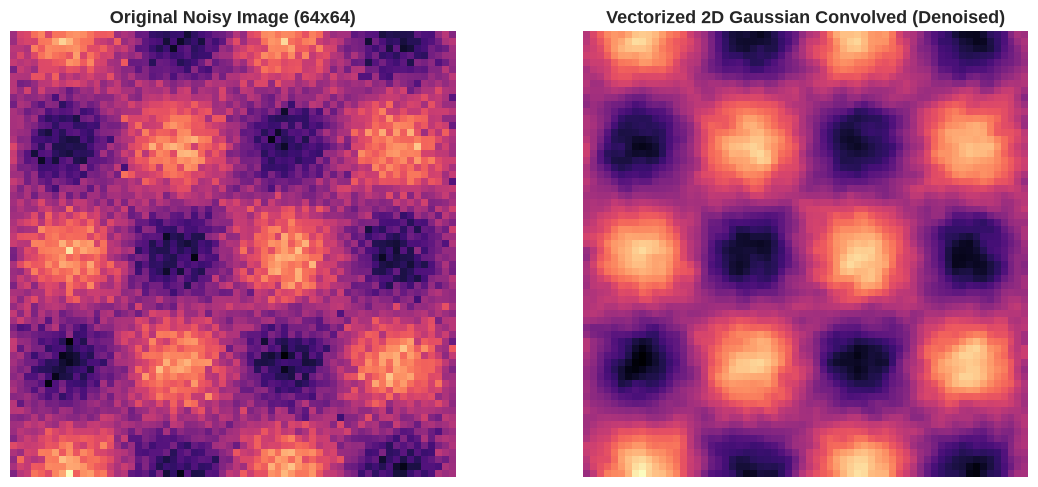

In [15]:
from numpy.lib.stride_tricks import sliding_window_view

# Generate a synthetic 2D test image (e.g., checkerboard + noise)
H, W = 64, 64
x_coords, y_coords = np.meshgrid(np.linspace(0, 4*np.pi, W), np.linspace(0, 4*np.pi, H))
synthetic_image = np.sin(x_coords) * np.cos(y_coords) + rng_prob.normal(0, 0.2, (H, W))

# Define a 3x3 Gaussian Blur Smoothing Kernel
gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16.0

def vectorized_convolve2d(image, kernel):
    k_h, k_w = kernel.shape
    # Pad image edges with boundary replication
    pad_h, pad_w = k_h // 2, k_w // 2
    padded = np.pad(image, ((pad_h, pad_h), (pad_w, pad_w)), mode='edge')
    # Create sliding windows of shape (H, W, k_h, k_w) without duplicating memory!
    windows = sliding_window_view(padded, (k_h, k_w))
    # Vectorized element-wise product and sum over kernel axes (-2, -1)
    convolved = np.sum(windows * kernel, axis=(-2, -1))
    return convolved

filtered_image = vectorized_convolve2d(synthetic_image, gaussian_kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(synthetic_image, cmap='magma')
axes[0].set_title("Original Noisy Image (64x64)", fontsize=13, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(filtered_image, cmap='magma')
axes[1].set_title("Vectorized 2D Gaussian Convolved (Denoised)", fontsize=13, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()

### Problem 4: Vectorized Monte Carlo Simulation (Geometric Brownian Motion)
In financial engineering and reinforcement learning, simulating stochastic paths (Geometric Brownian Motion) is essential:
$$S_{t} = S_0 \exp\left( \left(\mu - \frac{1}{2}\sigma^2\right)t + \sigma W_t \right)$$
Instead of simulating one path at a time in a loop, we simulate **10,000 independent price paths over 252 trading days simultaneously** in a single $(252, 10000)$ matrix using vectorized cumulative sums (`np.cumsum`).

Simulated 10000 paths over 252 steps.
Mean Final Price          : $108.19
95% Value at Risk (1-Year): 24.09%
95% Expected Shortfall    : 30.01%


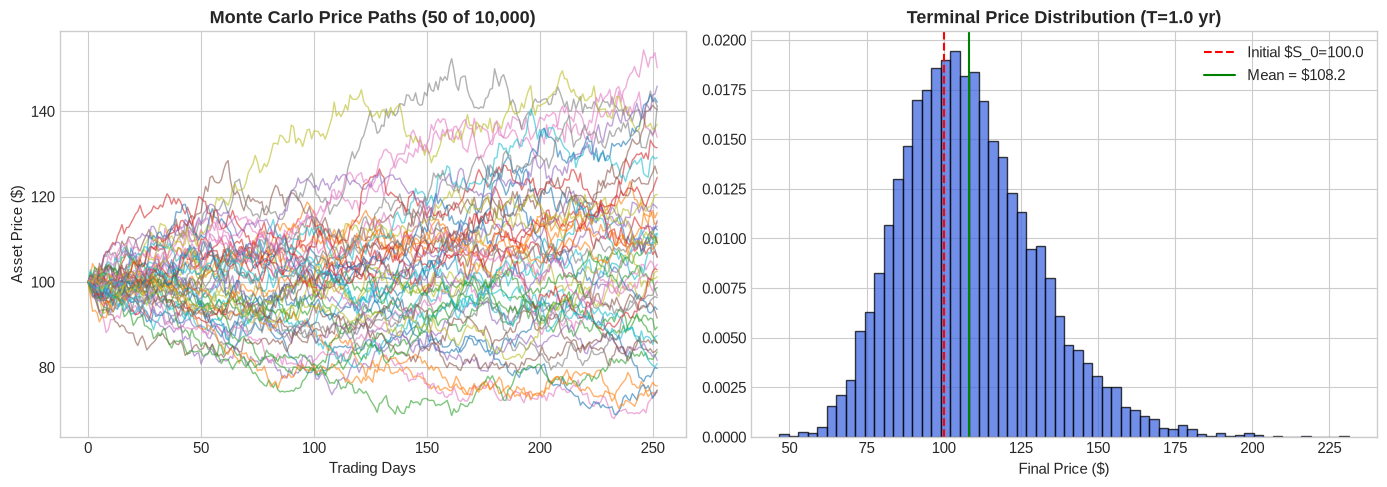

In [16]:
# Monte Carlo Parameters
S0 = 100.0         # Initial stock price
mu = 0.08          # Annual expected return (drift)
sigma = 0.20       # Annual volatility
T = 1.0            # Time horizon in years
N_days = 252       # Trading days
N_sims = 10000     # 10,000 parallel paths
dt = T / N_days

# Zero-loop simulation: generate all random daily shocks at once
daily_shocks = rng_prob.normal(0, np.sqrt(dt), size=(N_days, N_sims))
# Vectorized cumulative sum to compute the Brownian path W_t
drift = (mu - 0.5 * sigma**2) * dt
daily_log_returns = drift + sigma * daily_shocks
cumulative_log_returns = np.cumsum(daily_log_returns, axis=0)

# All 10,000 price trajectories computed in a single vectorized matrix expression
price_paths = S0 * np.exp(np.vstack([np.zeros((1, N_sims)), cumulative_log_returns]))

final_prices = price_paths[-1, :]
returns = (final_prices - S0) / S0

# Compute Risk Metrics: 95% and 99% Value at Risk (VaR) and Expected Shortfall (CVaR)
var_95 = -np.percentile(returns, 5)
cvar_95 = -np.mean(returns[returns <= -var_95])

print(f"Simulated {N_sims} paths over {N_days} steps.")
print(f"Mean Final Price          : ${np.mean(final_prices):.2f}")
print(f"95% Value at Risk (1-Year): {var_95 * 100:.2f}%")
print(f"95% Expected Shortfall    : {cvar_95 * 100:.2f}%")

# Visualize top 50 paths and final distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(price_paths[:, :50], alpha=0.6, linewidth=1)
ax1.set_title("Monte Carlo Price Paths (50 of 10,000)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Trading Days")
ax1.set_ylabel("Asset Price ($)")

ax2.hist(final_prices, bins=60, color='royalblue', edgecolor='black', alpha=0.75, density=True)
ax2.axvline(S0, color='red', linestyle='--', label=f'Initial $S_0={S0}')
ax2.axvline(np.mean(final_prices), color='green', linestyle='-', label=f'Mean = ${np.mean(final_prices):.1f}')
ax2.set_title("Terminal Price Distribution (T=1.0 yr)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Final Price ($)")
ax2.legend()
plt.tight_layout()
plt.show()

---
## ⏱️ 8. Performance Benchmark: Vectorized NumPy vs Pure Python

Now we put numbers to theory. We compare the execution speed of:
1. **Pure Python implementation** (using native `for` loops and `list`).
2. **Vectorized NumPy implementation** (using SIMD-accelerated C routines).

### Task: Multi-term Non-linear Polynomial Transformation
Compute $f(x) = 3.2 x^3 - 1.5 x^2 + 4.7 x - 2.1$ across varying array sizes from $N=10^3$ to $N=10^6$.

In [17]:
def python_poly(data_list):
    res = []
    for x in data_list:
        res.append(3.2 * (x ** 3) - 1.5 * (x ** 2) + 4.7 * x - 2.1)
    return res

def numpy_poly(data_array):
    return 3.2 * (data_array ** 3) - 1.5 * (data_array ** 2) + 4.7 * data_array - 2.1

sizes = [1_000, 10_000, 100_000, 500_000, 1_000_000]
py_times = []
np_times = []
speedups = []

for N in sizes:
    # Setup data
    py_data = [float(i % 100) / 10.0 for i in range(N)]
    np_data = np.array(py_data, dtype=np.float64)

    # Time Python Loop
    start = time.perf_counter()
    _ = python_poly(py_data)
    t_py = time.perf_counter() - start
    py_times.append(t_py)

    # Time NumPy Vectorized
    # Warmup
    _ = numpy_poly(np_data[:100])
    start = time.perf_counter()
    _ = numpy_poly(np_data)
    t_np = time.perf_counter() - start
    np_times.append(t_np)

    speedup = t_py / t_np
    speedups.append(speedup)
    print(f"N = {N:9,d} | Python: {t_py*1000:8.2f} ms | NumPy: {t_np*1000:7.2f} ms | Speedup: {speedup:6.1f}x")

N =     1,000 | Python:     0.15 ms | NumPy:    0.03 ms | Speedup:    4.8x
N =    10,000 | Python:     1.43 ms | NumPy:    0.36 ms | Speedup:    4.0x
N =   100,000 | Python:    14.32 ms | NumPy:    1.99 ms | Speedup:    7.2x
N =   500,000 | Python:    73.55 ms | NumPy:   11.27 ms | Speedup:    6.5x


N = 1,000,000 | Python:   147.93 ms | NumPy:   21.74 ms | Speedup:    6.8x


### Benchmark Visualization & Speedup Curves

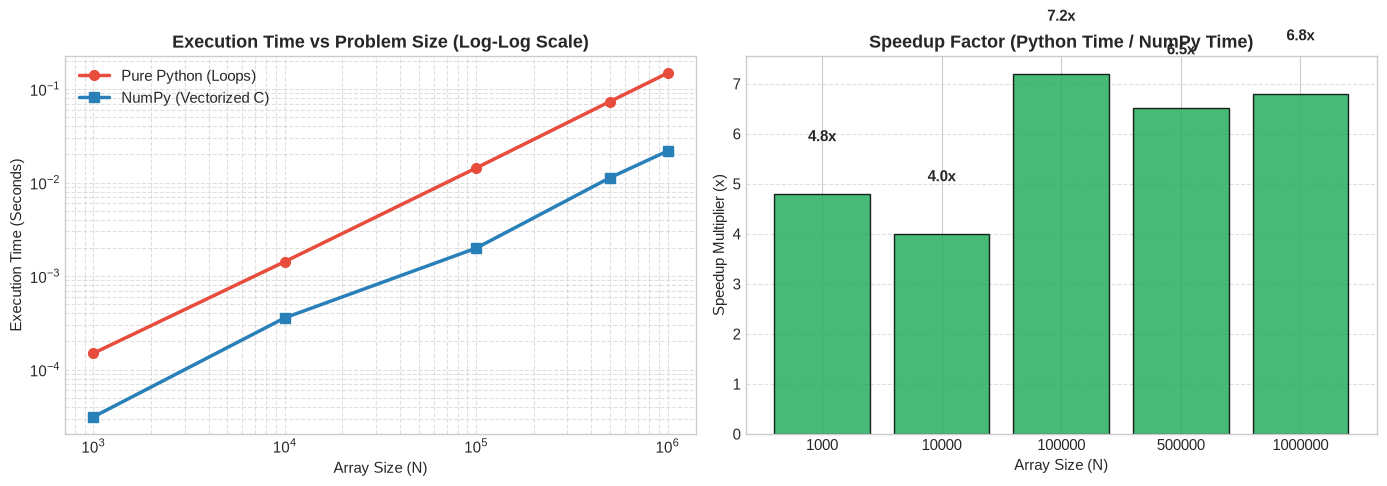

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Execution Time (Log-Log Scale)
ax1.plot(sizes, py_times, 'o-', color='#e74c3c', linewidth=2.5, markersize=7, label='Pure Python (Loops)')
ax1.plot(sizes, np_times, 's-', color='#2980b9', linewidth=2.5, markersize=7, label='NumPy (Vectorized C)')
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_title("Execution Time vs Problem Size (Log-Log Scale)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Array Size (N)", fontsize=11)
ax1.set_ylabel("Execution Time (Seconds)", fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(True, which="both", ls="--", alpha=0.6)

# Plot 2: Speedup Factor
bars = ax2.bar([str(s) for s in sizes], speedups, color='#27ae60', edgecolor='black', alpha=0.85)
ax2.set_title("Speedup Factor (Python Time / NumPy Time)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Array Size (N)", fontsize=11)
ax2.set_ylabel("Speedup Multiplier (x)", fontsize=11)
for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1, f'{yval:.1f}x', ha='center', va='bottom', fontweight='bold')
ax2.grid(axis='y', ls="--", alpha=0.6)

plt.tight_layout()
plt.show()

---
## 🎓 9. Why Vectorization is Crucial in Machine Learning Workflows

### The Architectural Tiers of Performance
| Dimension | Pure Python Loops | Vectorized NumPy (`ndarray`) |
| :--- | :--- | :--- |
| **Memory Allocation** | Fragmented object pointers across heap | Single contiguous byte buffer in RAM |
| **Cache Locality** | Frequent L1/L2/L3 cache misses | High spatial locality; fills CPU cache lines |
| **Instruction Execution** | 1 element per bytecode loop iteration | **SIMD** (AVX2, AVX-512, ARM NEON): 8–16 elements per instruction |
| **Dynamic Overhead** | Type checks & method dispatch on every op | Statically compiled C/Fortran routines |
| **Parallelism** | Bound by Python Global Interpreter Lock (GIL) | Releases GIL during underlying BLAS/LAPACK calls |

### The Bridge to Deep Learning (PyTorch, JAX, TensorFlow)
The modern AI stack is built entirely on the mathematical abstractions pioneered by NumPy:
1. **PyTorch `torch.Tensor`** and **JAX `jax.Array`** adopt NumPy's exact API design (broadcasting, shapes, strides, slicing, reductions).
2. Instead of running on CPU SIMD units, the tensor operations are dispatched to GPU Streaming Multiprocessors (SMs) and TPU Matrix Multiply Units (MXUs), achieving trillions of floating-point operations per second ($TFLOPS$).
3. **If your data pipeline relies on Python loops, your multi-thousand-dollar GPU will sit idle starving for data!** Writing vectorized NumPy transformations ensures the CPU feeds data fast enough to saturate hardware accelerators.

---
### 🏁 Conclusion & Next Steps
You have completed the **NumPy Playground**. You now possess the foundational intuition for zero-loop data engineering, spatial transformations, linear algebra, and performance optimization. Next, proceed to **`02_exploratory_data_analysis`** to master Pandas, Matplotlib, and Seaborn on a 40,000+ row production dataset!